In [1]:
import sys

sys.path.append("../src")
from types import SimpleNamespace

import numpy as np
import torch
import matplotlib.pyplot as plt
import arviz as az

from configs.load_config import load_config
from data_processing.load import load_dataset
from data_processing.utils import load_torch_model, load_checkpoint
from models.build import build_model
from training.evaluate import (
    evaluate_model,
    evaluate_numpyro,
)

In [2]:
model_cfg_BNN = load_config("../configs/model/bnn_gen_model_nowcast_01_weighted.yaml")
data_cfg = load_config(model_cfg_BNN.data.path)
file_name_BNN = "model_mw_gamma_extended_2026-03-28_14-17-43_nowcast_ELSPOT_NO1"

model_cfg_QRNN = load_config("../configs/model/torch_model_quantile.yaml")
file_name_QRNN = "WindPowerQuantile_weighted_2026-04-07_17-04-37_nowcast_gen_ELSPOT_NO1"

In [3]:
data_cfg.dataset = "forecast"
data_cfg.ensemble = SimpleNamespace(members=None, variance=False)

In [4]:
data = load_dataset(data_cfg)

Loading forecast data for ELSPOT NO1, ensemble members [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14]...
Loaded scaler parameters for ELSPOT NO1 and nowcast
  Saved at: 2026-04-07 15:22:40
  Split time: 2025-01-01 00:00:00+01:00
Dropping 15 gust columns not present in nowcast

Column mapping summary:
  Original columns: 94
  Renamed columns: 79
  Dropped columns: 15
  Final columns: 79

 Index([      0,       1,       2,       3,       4,       5,       6,       7,
             8,       9,
       ...
       6874202, 6874203, 6874204, 6874205, 6874206, 6874207, 6874208, 6874209,
       6874210, 6874211],
      dtype='int64', length=6761520)
All parks operational from 2022-10-26 22:00:00
Before 2-day ahead filtering: 323718 rows
After 2-day ahead filtering: 120222 rows
Lead time range: 34.0h to 61.0h


/Users/noemiweber/Documents/Studium/master/4.semester_norway/WindAIcompetition/notebooks/../src/data_processing/downtime.py:64: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  maintenance_events.drop(


Maintenance hours in operational period: 8
Preprocessing done. X_train shape: (18132, 6, 15, 10)
Preprocessing done. X_test shape: (1895, 6, 15, 10)


In [5]:
y_pred_list_BNN = []
y_pred_list_QRNN = []

for member in range(15):

    quantiles = torch.linspace(0, 1, model_cfg_QRNN.params.num_quantiles)

    # QRNN
    model_QRNN, checkpoint_QRNN = load_torch_model(
        file_name=file_name_QRNN, quantiles=quantiles
    )

    _, y_pred_QRNN = evaluate_model(
        model=model_QRNN,
        data=data,
        quantiles=quantiles,
        model_cfg=checkpoint_QRNN["model_cfg"],
        member=member,
    )
    y_pred_list_QRNN.append(y_pred_QRNN)

    # BNN
    checkpoint_BNN = load_checkpoint(file_name=file_name_BNN)
    model_BNN = build_model(checkpoint_BNN["model_cfg"], data)
    samples = checkpoint_BNN["samples"]
    _, y_pred_BNN, _, _, _, _ = evaluate_numpyro(
        model=model_BNN,
        samples=checkpoint_BNN["samples"],
        rng_key_predict=checkpoint_BNN["rng_key_predict"],
        data=data,
        model_cfg=checkpoint_BNN["model_cfg"],
        member=member,
    )

    y_pred_list_BNN.append(y_pred_BNN)

Loaded model: WindPowerQuantile_weighted_2026-04-07_17-04-37_nowcast_gen_ELSPOT_NO1.pt
  Model class: WindPowerQuantile_weighted
Choose member 0
Choose member 0
     rmse_median_train: tensor(61.5472)

   crps_train: tensor(32.2410)

   coverage_025_975_train: tensor(0.9158)

   coverage_0_50_train: tensor(0.4472)
Loading specified checkpoint: ../checkpoints/model_mw_gamma_extended_2026-03-28_14-17-43_nowcast_ELSPOT_NO1.pkl
RMSE train: 54.778553
CRPS train:  28.432998651592392
RMSE val: 70.09932
CRPS val:  37.39987140573555 

Loaded model: WindPowerQuantile_weighted_2026-04-07_17-04-37_nowcast_gen_ELSPOT_NO1.pt
  Model class: WindPowerQuantile_weighted
Choose member 1
Choose member 1
     rmse_median_train: tensor(69.5647)

   crps_train: tensor(37.4193)

   coverage_025_975_train: tensor(0.8766)

   coverage_0_50_train: tensor(0.4526)
Loading specified checkpoint: ../checkpoints/model_mw_gamma_extended_2026-03-28_14-17-43_nowcast_ELSPOT_NO1.pkl
RMSE train: 64.83748
CRPS train:  34.489

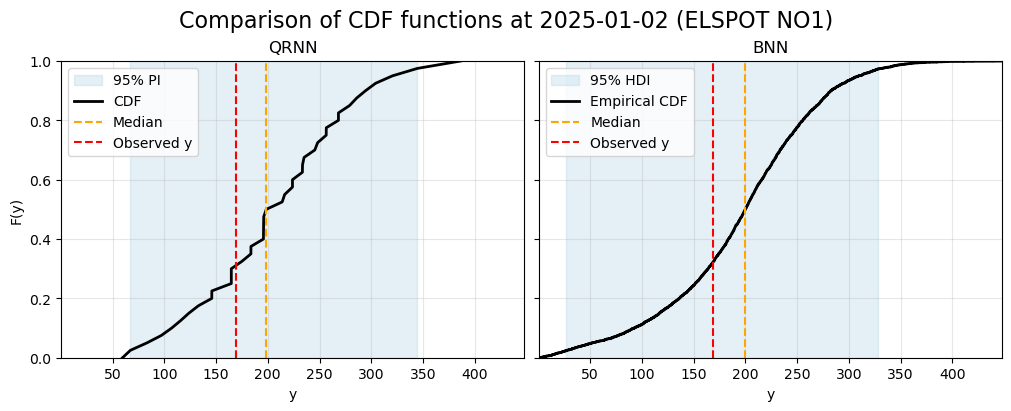

In [6]:
t = 40

# QRNN
ensemble = torch.stack(y_pred_list_QRNN, dim=0)  # [M, N, Q]
ensemble_mean = torch.mean(ensemble, dim=0)  # [N, Q]

quantiles = torch.linspace(0, 1, model_cfg_QRNN.params.num_quantiles)

q5_idx = torch.argmin(torch.abs(quantiles - 0.5)).item()
q025_idx = torch.argmin(torch.abs(quantiles - 0.025)).item()
q975_idx = torch.argmin(torch.abs(quantiles - 0.975)).item()

qrnn_cdf_x = ensemble_mean[t].numpy()
qrnn_cdf_y = quantiles.numpy()

qrnn_median = ensemble_mean[t][q5_idx].item()
qrnn_lower = ensemble_mean[t][q025_idx].item()
qrnn_upper = ensemble_mean[t][q975_idx].item()


# BNN
y_samples = np.concatenate(y_pred_list_BNN, axis=0)[:, t]


def compute_ecdf(samples):
    samples = np.sort(np.asarray(samples))
    n = len(samples)
    y = np.arange(1, n + 1) / n
    return samples, y


x_ecdf, F_ecdf = compute_ecdf(y_samples)

hdi_lower, hdi_upper = az.hdi(y_samples, hdi_prob=0.95)
bnn_median = np.median(y_samples)

# Observed value
y_true = float(data["Y_test_gen"][t])

# Shared x-limits
x_min = min(qrnn_cdf_x.min(), x_ecdf.min(), y_true, qrnn_lower, hdi_lower)
x_max = max(qrnn_cdf_x.max(), x_ecdf.max(), y_true, qrnn_upper, hdi_upper)

# Plot
fig, axes = plt.subplots(1, 2, figsize=(10, 4), sharey=True, constrained_layout=True)

# Left: QRNN
axes[0].fill_betweenx(
    y=[0, 1],
    x1=qrnn_lower,
    x2=qrnn_upper,
    color="#A6CEE3",
    alpha=0.3,
    label="95% PI",
)

axes[0].plot(
    qrnn_cdf_x,
    qrnn_cdf_y,
    lw=2,
    color="black",
    label="CDF",
)

axes[0].axvline(
    qrnn_median,
    color="orange",
    lw=1.5,
    linestyle="--",
    label="Median",
)

axes[0].axvline(
    y_true,
    color="red",
    lw=1.5,
    linestyle="--",
    label="Observed y",
)

axes[0].set_title("QRNN")
axes[0].set_xlabel("y")
axes[0].set_ylabel("F(y)")
axes[0].set_xlim(x_min, x_max)
axes[0].set_ylim(0, 1)
axes[0].legend()

# Right: BNN
axes[1].fill_betweenx(
    y=[0, 1],
    x1=hdi_lower,
    x2=hdi_upper,
    color="#A6CEE3",
    alpha=0.3,
    label="95% HDI",
)

axes[1].step(
    x_ecdf,
    F_ecdf,
    where="post",
    lw=2,
    color="black",
    label="Empirical CDF",
)

axes[1].axvline(
    bnn_median,
    color="orange",
    lw=1.5,
    linestyle="--",
    label="Median",
)

axes[1].axvline(
    y_true,
    color="red",
    lw=1.5,
    linestyle="--",
    label="Observed y",
)

axes[1].set_title("BNN")
axes[1].set_xlabel("y")
axes[1].set_xlim(x_min, x_max)
axes[1].legend()

axes[0].grid(alpha=0.3)
axes[1].grid(alpha=0.3)
date = data["X_test_timestamps"][t]

plt.suptitle(
    f"Comparison of CDF functions at {date.strftime("%Y-%m-%d")} ({model_cfg_BNN.data.bid_zone})",
    fontsize=16,
)
plt.show()
# plt.savefig(f"../plots/compare_cdfs_{model_cfg_BNN.data.bid_zone}.pdf")

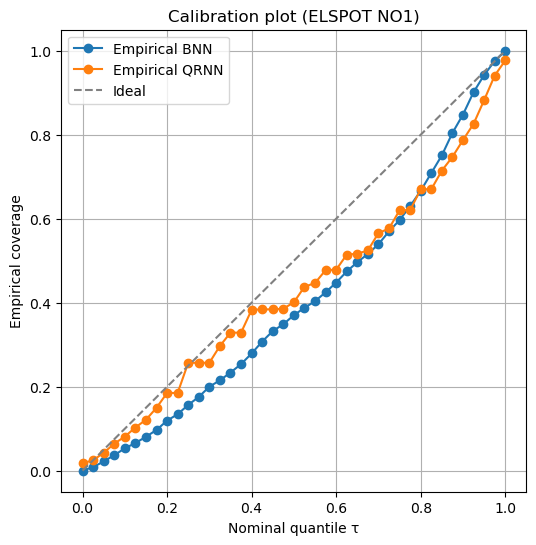

In [7]:
# y_pred: (S, N)
pp_samples_stacked = np.concatenate(y_pred_list_BNN, axis=0)

quantiles = torch.linspace(0, 1, model_cfg_QRNN.params.num_quantiles)


emp_cov_BNN = np.mean(
    np.asarray(data["Y_test_gen"])[:, None]
    <= np.quantile(pp_samples_stacked, quantiles, axis=0).T,
    axis=0,
)
emp_cov_QRNN = np.mean(
    np.asarray(data["Y_test_gen"])[:, None]
    <= np.mean(np.stack(y_pred_list_QRNN, axis=0), axis=0),
    axis=0,
)


plt.figure(figsize=(6, 6))
plt.plot(quantiles, emp_cov_BNN, "o-", label="Empirical BNN")
plt.plot(quantiles, emp_cov_QRNN, "o-", label="Empirical QRNN")
plt.plot([0, 1], [0, 1], "--", color="gray", label="Ideal")
plt.xlabel("Nominal quantile τ")
plt.ylabel("Empirical coverage")
plt.title(f"Calibration plot ({model_cfg_BNN.data.bid_zone})")
plt.legend()
plt.grid(True)